# Phase 6 · Customers who do not come back

**Business question 4:** Why do some customers not come back, and who is about to leave?

In this notebook we define churn precisely, build the dataset without using information from the future, look at which characteristics of the first purchase are associated with coming back, and train two models to predict it. We explain the best model with SHAP and use it to score the most recent customers.

**Input:** the SQLite database `olist.db`. The queries are in the `sql/` folder.

**Outputs** in `data/processed/`:

| File | Content |
|---|---|
| `churn_dataset.csv` | One row per customer in the modeling cohort, with the features and the target |
| `churn_model_metrics.csv` | Evaluation metrics of both models |
| `customer_return_scores.csv` | Return score and risk group of the most recent customers |

## 1. Libraries, paths, chart style and SQL helper

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.proportion import proportion_confint

PROCESSED = Path("..") / "data" / "processed"
DATABASE = PROCESSED / "olist.db"
SQL_DIR = Path("..") / "sql"
FIGURES = Path("..") / "reports" / "figures"
pd.set_option("display.max_columns", 40)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#898781"
LIGHT_GRAY = "#c3c2b7"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": LIGHT_GRAY,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": SECONDARY_INK,
    "ytick.color": SECONDARY_INK,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
})

RANDOM_STATE = 42


def run_sql(name, show=True, parse_dates=None, **params):
    # Reads sql/<name>.sql, prints it and returns the result as a DataFrame
    query = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(query)
    with closing(sqlite3.connect(DATABASE)) as connection:
        return pd.read_sql_query(query, connection, params=params, parse_dates=parse_dates)


def run_sql_script(name, show=True):
    # Runs a file with several statements, such as the creation of a view
    script = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(script)
    with closing(sqlite3.connect(DATABASE)) as connection:
        connection.executescript(script)

## 2. Why we do not use RFM segmentation

The proposal planned an RFM segmentation, which scores every customer by Recency, Frequency and Monetary value. Before building it we check whether frequency varies enough in this dataset to separate customers. We count, for every customer, their orders and their **purchase occasions**: the distinct days on which they bought. Several orders on the same day are a single purchase split across sellers, not a customer who came back.

In [2]:
frequency = run_sql("purchase_frequency")

print(f"Customers: {len(frequency):,}")
print(f"Customers with more than one order: {(frequency['orders'] > 1).sum():,}")
print(f"Customers with more than one purchase occasion: {(frequency['purchase_occasions'] > 1).sum():,}")

(
    frequency["purchase_occasions"].clip(upper=3)
    .value_counts(normalize=True).sort_index().mul(100).round(2)
    .rename(index={3: "3 or more"}).to_frame("customers_pct")
)

-- Orders and purchase occasions (distinct purchase days) of every customer
SELECT
    customer_unique_id,
    COUNT(*) AS orders,
    COUNT(DISTINCT date(purchase_date)) AS purchase_occasions
FROM orders
GROUP BY customer_unique_id;



Customers: 93,350
Customers with more than one order: 2,801
Customers with more than one purchase occasion: 2,015


,customers_pct
purchase_occasions,
1,97.84
2,2.00
3 or more,0.16


Only 2,015 of the 93,350 customers (2.2%) bought on more than one day. Another 786 placed several orders, but all on the same day, so they did not really come back. With 97.8% of the customers at a frequency of one, the F in RFM separates nobody: almost every customer would get the same frequency score, and segments such as "Champions" or "Loyal customers" would be nearly empty.

So we leave RFM out and focus on the question that matters for the business: which customers come back after their first purchase, and whether that can be anticipated. In a business where customers buy repeatedly, such as spare parts for machinery, RFM becomes useful again.

## 3. How we define churn

"A customer who does not come back" needs a precise definition before we can predict it. These are the decisions, each one justified with the data:

| Element | Definition | Why |
|---|---|---|
| Unit | Customer (`customer_unique_id`) | We predict the behavior of a person, not of an order. |
| Purchase | A purchase occasion: all orders placed on the same day | Same-day orders are one purchase split across sellers, not a return. |
| Prediction moment | When the first purchase has been delivered and, if the customer reviewed it, reviewed | At that moment we know the delivery time, the delay and the review, so the model can use them without looking into the future. |
| Prediction window | 180 days after the prediction moment | Three quarters of the customers who come back do so within 180 days, and it is the window that leaves the most returning customers to learn from. |
| Target | `returned = 1` if the customer makes a new purchase within the window; churn otherwise | Churn is the opposite of the target: `churn = 1 - returned`. |
| Cohort | Customers whose first purchase is from 2017 on and whose full window ends by August 21, 2018 | 2016 is incomplete, and the data stops being complete on August 22, 2018 (Phase 1). |
| Exclusions | Customers who came back before the prediction moment | They returned before a prediction could be made. |
| Allowed features | Only information about the first purchase, known at the prediction moment | Anything else would leak the answer into the model. |
| Forbidden features | Number of orders, total spend, recency, RFM scores | They are computed with later purchases, so they contain the target. |
| Validation | Temporal: train on the oldest customers, test on the most recent ones | It mimics how the model would be used: learning from the past to predict the future. |

The query builds one row per customer with their first purchase occasion. A window function (`ROW_NUMBER`) numbers each customer's occasions by date, so the first and the second occasion can be picked directly.

In [3]:
run_sql_script("orders_with_region_view", show=False)
first_purchases = run_sql(
    "churn_first_purchase",
    parse_dates=["purchase_day", "delivered_date", "review_date", "prediction_date", "second_purchase_day"],
)
print(f"Customers: {len(first_purchases):,}")

-- One row per customer describing their first purchase occasion, plus the day of their
-- second purchase occasion, if there was one.
-- A purchase occasion is a day on which the customer placed at least one order: several
-- orders placed on the same day are one purchase split across sellers, not a return.
WITH occasion_orders AS (
    SELECT
        o.*,
        date(o.purchase_date) AS purchase_day,
        -- Category and payment method of the order with the highest revenue on that day
        FIRST_VALUE(o.main_category) OVER same_day AS occasion_main_category,
        FIRST_VALUE(o.payment_type) OVER same_day AS occasion_payment_type
    FROM orders_with_region AS o
    WINDOW same_day AS (
        PARTITION BY o.customer_unique_id, date(o.purchase_date)
        ORDER BY o.revenue DESC, o.order_id
    )
),
occasions AS (
    SELECT
        customer_unique_id,
        purchase_day,
        MIN(customer_state) AS customer_state,
        MIN(region) AS region,
        MIN(occasion_

Customers: 93,350


### Why a 180-day window

The window has to be long enough to catch most of the customers who come back, but every extra day of window leaves out customers whose window is not complete by the end of the data. We measure how long returning customers take to come back, and how many customers and returns each candidate window leaves for the model.

In [4]:
LAST_COMPLETE_DAY = pd.Timestamp("2018-08-21")

returners = first_purchases[first_purchases["second_purchase_day"].notna()]
days_to_return = (returners["second_purchase_day"] - returners["purchase_day"]).dt.days
days_to_prediction = (first_purchases["prediction_date"] - first_purchases["purchase_day"]).dt.days

print(f"Customers with a second purchase occasion: {len(returners):,}")
print(f"Median days between the first and the second purchase: {days_to_return.median():.0f}")
for days in (90, 180, 365):
    print(f"  came back within {days} days: {(days_to_return <= days).mean():.1%}")
print(f"Median days from the first purchase to the prediction moment: {days_to_prediction.median():.0f}")


def build_cohort(window_days):
    # Customers from 2017 whose whole window is observed and who did not return before the prediction moment
    window = pd.Timedelta(days=window_days)
    observed = first_purchases["prediction_date"] + window < LAST_COMPLETE_DAY + pd.Timedelta(days=1)
    returned_early = (
        first_purchases["second_purchase_day"].notna()
        & (first_purchases["second_purchase_day"] <= first_purchases["prediction_date"])
    )
    eligible = first_purchases[(first_purchases["purchase_day"] >= "2017-01-01") & observed & ~returned_early]
    returned = eligible["second_purchase_day"].notna() & (eligible["second_purchase_day"] <= eligible["prediction_date"] + window)
    return eligible, returned


window_options = []
for window_days in (90, 180, 365):
    eligible, returned = build_cohort(window_days)
    window_options.append({
        "window_days": window_days,
        "customers": len(eligible),
        "returned": int(returned.sum()),
        "return_rate_pct": returned.mean() * 100,
        "last_first_purchase": f"{eligible['purchase_day'].max():%Y-%m-%d}",
    })
pd.DataFrame(window_options).set_index("window_days").round(2)

Customers with a second purchase occasion: 2,015
Median days between the first and the second purchase: 74
  came back within 90 days: 54.9%
  came back within 180 days: 75.9%
  came back within 365 days: 95.8%
Median days from the first purchase to the prediction moment: 11


,customers,returned,return_rate_pct,last_first_purchase
window_days,,,,
90,71538,757,1.06,2018-05-20
180,49936,875,1.75,2018-02-19
365,18305,562,3.07,2017-08-17


Returning customers take a median of 74 days to come back: 54.9% return within 90 days, 75.9% within 180 and 95.8% within a year. The prediction moment arrives a median of 11 days after the first purchase.

A longer window catches more returns but leaves fewer customers with a complete window. With 90 days, almost half of the customers who do come back (45.1%) would be labeled as churned only because they took more than three months. With 365 days, only customers whose first purchase was before August 18, 2017 could be used, and the model would learn from 562 returns. The 180-day window catches three quarters of the returns and leaves the most returns to learn from (875), so it is the best balance.

### Building the cohort

In [5]:
WINDOW = pd.Timedelta(days=180)

# The window must end by the last complete day of data
window_is_observed = first_purchases["prediction_date"] + WINDOW < LAST_COMPLETE_DAY + pd.Timedelta(days=1)
returned_before_prediction = (
    first_purchases["second_purchase_day"].notna()
    & (first_purchases["second_purchase_day"] <= first_purchases["prediction_date"])
)

funnel = [("All customers", len(first_purchases))]
cohort = first_purchases[first_purchases["purchase_day"] >= "2017-01-01"]
funnel.append(("First purchase from January 2017", len(cohort)))
cohort = cohort[window_is_observed.loc[cohort.index]]
funnel.append(("Full 180-day window observed", len(cohort)))
cohort = cohort[~returned_before_prediction.loc[cohort.index]].copy()
funnel.append(("Did not come back before the prediction moment", len(cohort)))

cohort["returned"] = (
    cohort["second_purchase_day"].notna()
    & (cohort["second_purchase_day"] <= cohort["prediction_date"] + WINDOW)
).astype(int)

print(f"First purchases in the cohort: {cohort['purchase_day'].min():%Y-%m-%d} to {cohort['purchase_day'].max():%Y-%m-%d}")
print(f"Customers who came back within 180 days: {cohort['returned'].sum():,} ({cohort['returned'].mean():.2%})")
print(f"Churn rate: {1 - cohort['returned'].mean():.2%}")
pd.DataFrame(funnel, columns=["step", "customers"])

First purchases in the cohort: 2017-01-05 to 2018-02-19
Customers who came back within 180 days: 875 (1.75%)
Churn rate: 98.25%


,step,customers
0,All customers,93350
1,First purchase from January 2017,93086
2,Full 180-day window observed,50105
3,Did not come back before the prediction moment,49936


### Checks against data leakage

These checks stop the notebook if any feature could contain information from after the prediction moment.

In [6]:
leakage_checks = pd.Series({
    "Prediction moment is on or after the delivery": (cohort["prediction_date"] >= cohort["delivered_date"]).all(),
    "Prediction moment is on or after the review":
        (cohort["review_date"].isna() | (cohort["prediction_date"] >= cohort["review_date"])).all(),
    "Every return in the target happens after the prediction moment":
        (cohort.loc[cohort["returned"] == 1, "second_purchase_day"] > cohort.loc[cohort["returned"] == 1, "prediction_date"]).all(),
    "Every window ends by the last complete day": (cohort["prediction_date"] + WINDOW <= LAST_COMPLETE_DAY + pd.Timedelta(days=1)).all(),
})
assert leakage_checks.all(), leakage_checks[~leakage_checks]
leakage_checks.to_frame("passed")

,passed
Prediction moment is on or after the delivery,True
Prediction moment is on or after the review,True
Every return in the target happens after the prediction moment,True
Every window ends by the last complete day,True


The cohort has 49,936 customers whose first purchase happened between January 5, 2017 and February 19, 2018. Of them, 875 (1.75%) came back within 180 days, so the churn rate is 98.25%. On the way we excluded the customers whose first purchase was in 2016, almost 43,000 customers whose 180-day window was not complete by August 21, 2018, and 169 who came back before the prediction moment.

The four leakage checks pass: every feature is known at the prediction moment, and every return counted in the target happens after it.

## 4. What is associated with coming back

Before modeling we compare the return rate across groups of customers. Because only 1.75% of customers come back, small differences between groups can be pure chance. So every rate comes with its **95% confidence interval** (Wilson method): if the intervals of two groups overlap a lot, the data does not show a real difference between them.

In [7]:
cohort["review_group"] = cohort["review_score"].round().map(
    lambda score: "No review" if pd.isna(score) else str(int(score))
)
cohort["delivery"] = np.where(cohort["is_late"] == 1, "Late", "On time")
cohort["orders_first_day"] = np.where(cohort["orders"] > 1, "2 or more", "1")


def return_rate_by(column, order=None):
    grouped = cohort.groupby(column)["returned"].agg(customers="size", returned="sum")
    if order is not None:
        grouped = grouped.loc[order]
    low, high = proportion_confint(grouped["returned"], grouped["customers"], alpha=0.05, method="wilson")
    grouped["return_rate_pct"] = grouped["returned"] / grouped["customers"] * 100
    grouped["ci_low_pct"] = low * 100
    grouped["ci_high_pct"] = high * 100
    return grouped


comparisons = {
    "Review score of the first purchase": return_rate_by("review_group", ["1", "2", "3", "4", "5", "No review"]),
    "First delivery": return_rate_by("delivery", ["On time", "Late"]),
    "Region": return_rate_by("region", ["Southeast", "South", "Central-West", "Northeast", "North"]),
    "Orders on the first purchase day": return_rate_by("orders_first_day", ["1", "2 or more"]),
}
pd.concat(comparisons, names=["comparison", "group"]).round(2)

customers  returned  \
comparison                         group                               
Review score of the first purchase 1                  4344        62   
                                   2                  1539        20   
                                   3                  4265        73   
                                   4                 10069       162   
                                   5                 29353       553   
                                   No review           366         5   
First delivery                     On time           47405       840   
                                   Late               2531        35   
Region                             Southeast         33949       647   
                                   South              7289       113   
                                   Central-West       2875        42   
                                   Northeast          4824        59   
                                   North               999        14   
Orders on the first purchase day   1                 49389       855   
                                   2 or more           547        20   

                                                 return_rate_pct  ci_low_pct  \
comparison                         group                                       
Review score of the first purchase 1                        1.43        1.12   
                                   2                        1.30        0.84   
                                   3                        1.71        1.36   
                                   4                        1.61        1.38   
                                   5                        1.88        1.73   
                                   No review                1.37        0.58   
First delivery                     On time                  1.77        1.66   
                                   Late                     1.38        1.00   
Region                             Southeast                1.91        1.77   
                                   South                    1.55        1.29   
                                   Central-West             1.46        1.08   
                                   Northeast                1.22        0.95   
                                   North                    1.40        0.84   
Orders on the first purchase day   1                        1.73        1.62   
                                   2 or more                3.66        2.38   

                                                 ci_high_pct  
comparison                         group                      
Review score of the first purchase 1                    1.83  
                                   2                    2.00  
                                   3                    2.15  
                                   4                    1.87  
                                   5                    2.05  
                                   No review            3.16  
First delivery                     On time              1.89  
                                   Late                 1.92  
Region                             Southeast            2.06  
                                   South                1.86  
                                   Central-West         1.97  
                                   Northeast            1.57  
                                   North                2.34  
Orders on the first purchase day   1                    1.85  
                                   2 or more            5.58

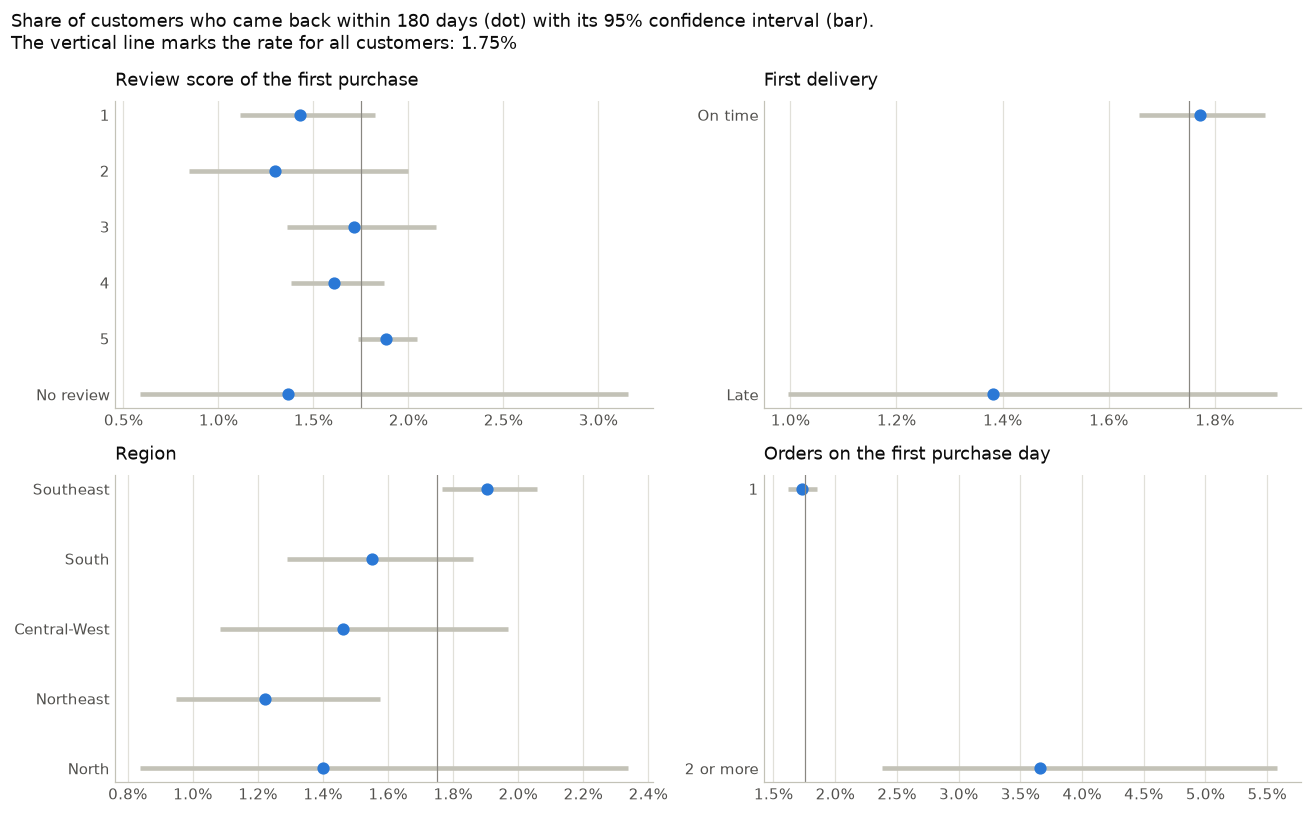

In [8]:
overall_rate = cohort["returned"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (title, table) in zip(axes.flat, comparisons.items()):
    positions = np.arange(len(table))[::-1]
    ax.hlines(positions, table["ci_low_pct"], table["ci_high_pct"], color=LIGHT_GRAY, linewidth=3)
    ax.plot(table["return_rate_pct"], positions, "o", color=BLUE, markersize=7)
    ax.axvline(overall_rate, color=GRAY, linewidth=0.8)
    ax.set_yticks(positions, table.index)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(lambda value, _: f"{value:.1f}%")
    ax.grid(axis="y", visible=False)
fig.suptitle("Share of customers who came back within 180 days (dot) with its 95% confidence interval (bar).\n"
             f"The vertical line marks the rate for all customers: {overall_rate:.2f}%",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIGURES / "06_return_rate_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

We also compare the month of the first purchase and the main category of the 12 categories with the most customers:

In [9]:
cohort["first_month"] = cohort["purchase_day"].dt.month
by_month = return_rate_by("first_month", list(range(1, 13))).rename(index=str)
top_categories = cohort["main_category"].value_counts().head(12).index
by_category = return_rate_by("main_category").loc[top_categories].sort_values("return_rate_pct")
pd.concat(
    {"Month of the first purchase": by_month, "Main category (12 largest)": by_category},
    names=["comparison", "group"],
).round(2)

customers  returned  \
comparison                  group                                        
Month of the first purchase 1                           7155       111   
                            2                           3164        51   
                            3                           2499        45   
                            4                           2248        40   
                            5                           3432        67   
                            6                           3028        64   
                            7                           3738        68   
                            8                           4047        96   
                            9                           3984        85   
                            10                          4316        69   
                            11                          7018       100   
                            12                          5307        79   
Main category (12 largest)  Cool stuff                  2425        26   
                            Toys                        2518        34   
                            Housewares                  2628        38   
                            Computers accessories       3129        46   
                            Telephony                   2302        34   
                            Watches gifts               2371        36   
                            Health beauty               3846        74   
                            Furniture decor             3399        69   
                            Garden tools                2095        43   
                            Perfumery                   1800        38   
                            Bed bath table              4924       113   
                            Sports leisure              4004        97   

                                                   return_rate_pct  \
comparison                  group                                    
Month of the first purchase 1                                 1.55   
                            2                                 1.61   
                            3                                 1.80   
                            4                                 1.78   
                            5                                 1.95   
                            6                                 2.11   
                            7                                 1.82   
                            8                                 2.37   
                            9                                 2.13   
                            10                                1.60   
                            11                                1.42   
                            12                                1.49   
Main category (12 largest)  Cool stuff                        1.07   
                            Toys                              1.35   
                            Housewares                        1.45   
                            Computers accessories             1.47   
                            Telephony                         1.48   
                            Watches gifts                     1.52   
                            Health beauty                     1.92   
                            Furniture decor                   2.03   
                            Garden tools                      2.05   
                            Perfumery                         2.11   
                            Bed bath table                    2.29   
                            Sports leisure                    2.42   

                                                   ci_low_pct  ci_high_pct  
comparison                  group                                           
Month of the first purchase 1                            1.29         1.86  
                            2                            1.23         2.11

Three differences are clear, because their confidence intervals do not overlap:

- Region: 1.91% of the customers in the Southeast came back, against 1.22% in the Northeast. This is consistent with Phase 5, where customers far from the sellers wait longer and pay more for freight.
- Orders on the first day: customers who placed two or more orders on their first day came back twice as often (3.66% against 1.73%). Buying from several sellers at once may signal a customer who already feels comfortable with the platform.
- Month of the first purchase: customers who started in November or December came back less (1.42% and 1.49%) than those who started in August (2.37%). The categories point in the same direction: among the largest categories, Cool stuff (1.07%) and Toys (1.35%) have the lowest return rates, while Bed bath table (2.29%) and Sports leisure (2.42%) have the highest. A possible reading is that gifts and holiday purchases are one-off, while everyday needs bring customers back. The data suggests it but cannot confirm it.

Two differences that seem intuitive are not conclusive. Customers with a 5-star review came back more often than those with a 1-star review (1.88% against 1.43%), and customers with on-time deliveries more often than those with late ones (1.77% against 1.38%). In both cases the intervals overlap, so the differences could be due to chance.

## 5. Predictive models

The features describe only the first purchase and are all known at the prediction moment:

| Group | Features |
|---|---|
| Value | revenue, units, freight, freight as a share of the total, installments, orders on the first day |
| Delivery | delivery days, delay days, whether the delivery was late |
| Review | review score, whether there was a review, whether it had a written comment |
| Customer and product | region, payment method, main category, month of the first purchase |

We compare a **logistic regression**, easy to interpret, with a **random forest**, which can capture nonlinear relationships. Both use `class_weight` so that the 1.75% of customers who come back are not ignored during training. The split is temporal: customers whose first purchase was before October 2017 train the models, and later customers test them.

In [10]:
cohort["freight_share"] = cohort["freight_value"] / (cohort["revenue"] + cohort["freight_value"])
cohort["has_review"] = cohort["review_score"].notna().astype(int)
cohort["has_comment"] = cohort["has_comment"].fillna(0).astype(int)
cohort["purchase_month"] = cohort["purchase_day"].dt.month.astype(str)

NUMERIC = ["revenue", "units", "freight_value", "freight_share", "installments", "orders",
           "delivery_days", "delay_days", "review_score"]
BINARY = ["is_late", "has_review", "has_comment"]
CATEGORICAL = ["region", "payment_type", "main_category", "purchase_month"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

SPLIT_DATE = pd.Timestamp("2017-10-01")
train = cohort[cohort["purchase_day"] < SPLIT_DATE]
test = cohort[cohort["purchase_day"] >= SPLIT_DATE]

pd.DataFrame({
    "customers": [len(train), len(test)],
    "returned": [train["returned"].sum(), test["returned"].sum()],
    "return_rate_pct": [train["returned"].mean() * 100, test["returned"].mean() * 100],
    "first_purchases": [f"{train['purchase_day'].min():%Y-%m-%d} to {train['purchase_day'].max():%Y-%m-%d}",
                        f"{test['purchase_day'].min():%Y-%m-%d} to {test['purchase_day'].max():%Y-%m-%d}"],
}, index=["train", "test"]).round(2)

,customers,returned,return_rate_pct,first_purchases
train,25314,502,1.98,2017-01-05 to 2017-09-30
test,24622,373,1.51,2017-10-01 to 2018-02-19


In [11]:
def preprocessing():
    # Missing review scores are filled with the median; the has_review flag keeps the information
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         NUMERIC + BINARY),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False), CATEGORICAL),
    ])


candidates = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=50,
                                            class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
}

fitted, scores, metrics = {}, {}, []
for name, estimator in candidates.items():
    model = Pipeline([("prep", preprocessing()), ("model", estimator)]).fit(train[FEATURES], train["returned"])
    score = model.predict_proba(test[FEATURES])[:, 1]
    in_top_10 = score >= np.quantile(score, 0.9)
    fitted[name], scores[name] = model, score
    metrics.append({
        "model": name,
        "roc_auc": roc_auc_score(test["returned"], score),
        "pr_auc": average_precision_score(test["returned"], score),
        "base_rate": test["returned"].mean(),
        "top_10pct_capture": test["returned"][in_top_10].sum() / test["returned"].sum(),
        "top_10pct_precision": test["returned"][in_top_10].mean(),
    })

metrics = pd.DataFrame(metrics).set_index("model")
metrics.round(4)

,roc_auc,pr_auc,base_rate,top_10pct_capture,top_10pct_precision
model,,,,,
Logistic regression,0.5575,0.0185,0.0151,0.1367,0.0207
Random forest,0.5713,0.0194,0.0151,0.1501,0.0227


How to read these metrics:

- **ROC AUC** is the probability that a customer who came back gets a higher score than one who did not. 0.5 means the model ranks customers at random; 1 means it ranks them perfectly.
- **PR AUC** (average precision) summarizes how precise the model is when it looks for the customers who come back. It should be compared with the base rate, the share of customers who come back, which is what a random model would get.
- **Top 10% capture** is the share of all returning customers found among the 10% of customers with the highest score. A random selection would capture 10%.

The gains curve extends the last metric to every share of customers: how many of the returning customers we would find if we contacted a given share of customers, starting with the highest scores.

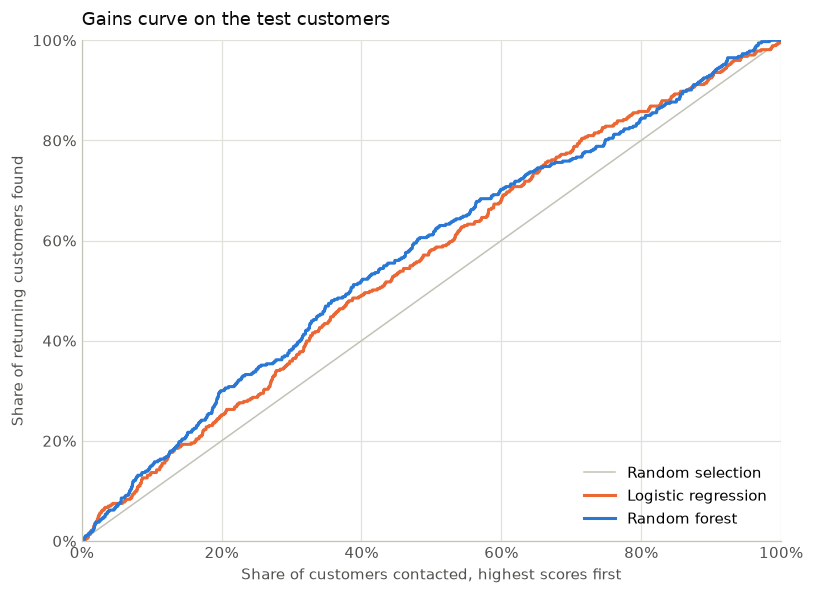

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot([0, 100], [0, 100], color=LIGHT_GRAY, linewidth=1, label="Random selection")
for (name, score), color in zip(scores.items(), [ORANGE, BLUE]):
    order = np.argsort(-score)
    captured = np.cumsum(test["returned"].to_numpy()[order]) / test["returned"].sum() * 100
    contacted = np.arange(1, len(order) + 1) / len(order) * 100
    ax.plot(contacted, captured, color=color, linewidth=2, label=name)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_title("Gains curve on the test customers")
ax.set_xlabel("Share of customers contacted, highest scores first")
ax.set_ylabel("Share of returning customers found")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "06_gains_curve.png", dpi=150, bbox_inches="tight")
plt.show()

The random forest is slightly better than the logistic regression, but both models are weak. The random forest reaches a ROC AUC of 0.571, where 0.5 would be a random ranking, and a PR AUC of 0.019 against a base rate of 0.015. The 10% of test customers with the highest scores contain 15.0% of the customers who came back, when a random selection would contain 10%, and 2.27% of them came back, against 1.51% of all test customers.

In the gains curve both models stay close to the diagonal. The honest conclusion is that the first purchase says little about whether a customer will come back: the model finds returning customers 50% better than chance (15.0% against 10%), but it misses most of them. That is a finding in itself. In this dataset, coming back probably depends on things the data does not record, such as whether the customer needs the product again, prices at competitors or any contact after the purchase.

## 6. What the model relies on (SHAP)

SHAP values measure how much each feature pushes a customer's score up or down compared with the average prediction. We compute them for the better model on a sample of 3,000 test customers and add up the categories of each categorical feature, so every original feature gets a single importance.

SHAP explains **the model**, not the customers: a feature with a large SHAP value is associated with the model's predictions, which does not mean that it causes customers to come back or to leave.

In [13]:
best_name = metrics["roc_auc"].idxmax()
best_model = fitted[best_name]
print(f"Model explained: {best_name}")

sample = test[FEATURES].sample(3000, random_state=RANDOM_STATE)
transformed = best_model.named_steps["prep"].transform(sample)
feature_names = best_model.named_steps["prep"].get_feature_names_out()

estimator = best_model.named_steps["model"]
if isinstance(estimator, RandomForestClassifier):
    explainer = shap.TreeExplainer(estimator)
else:
    explainer = shap.LinearExplainer(estimator, transformed)
shap_values = explainer.shap_values(transformed)
# For classifiers, keep the values for the positive class (customer came back)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]


def original_feature(name):
    # Maps a transformed column name, such as cat__region_South, back to its original feature
    column = name.split("__", 1)[1]
    for feature in CATEGORICAL:
        if column.startswith(f"{feature}_"):
            return feature
    return column


importance = (
    pd.DataFrame(np.abs(shap_values), columns=[original_feature(name) for name in feature_names])
    .T.groupby(level=0).sum().T
    .mean().sort_values(ascending=False)
)

# Direction for numeric and binary features: correlation between the feature and its SHAP value
direction = {}
for position, name in enumerate(feature_names):
    feature = original_feature(name)
    if feature in NUMERIC + BINARY:
        correlation = pd.Series(transformed[:, position]).corr(pd.Series(shap_values[:, position]), method="spearman")
        direction[feature] = "higher value, higher score" if correlation > 0 else "higher value, lower score"

shap_table = importance.to_frame("mean_abs_shap")
shap_table["direction"] = [direction.get(feature, "depends on the category") for feature in shap_table.index]
shap_table.head(10).round(4)

Model explained: Random forest


,mean_abs_shap,direction
main_category,0.0361,depends on the category
delivery_days,0.0149,"higher value, lower score"
purchase_month,0.0142,depends on the category
review_score,0.0134,"higher value, higher score"
region,0.0107,depends on the category
installments,0.0103,"higher value, higher score"
freight_share,0.0101,"higher value, higher score"
freight_value,0.0088,"higher value, higher score"
revenue,0.0085,"higher value, higher score"
delay_days,0.0072,"higher value, higher score"


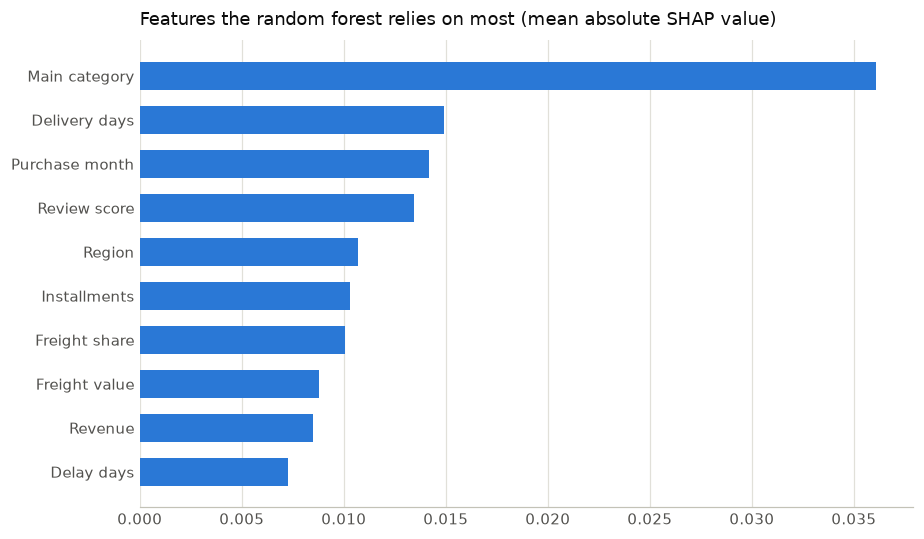

In [14]:
top = importance.head(10).iloc[::-1]
readable_names = top.index.str.replace("_", " ").str.capitalize()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(readable_names, top.to_numpy(), color=BLUE, height=0.65)
ax.set_title(f"Features the {best_name.lower()} relies on most (mean absolute SHAP value)")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "06_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

The model relies most on the main category of the first purchase, followed by delivery days, the month of the purchase, the review score and the region. These are the same features that showed differences in section 4, and their directions are consistent: longer deliveries push the score down and better reviews push it up.

Some weaker features show directions that are harder to interpret: more delay days push the score up, while more delivery days push it down. Both measure related things, and with such a weak signal the model splits their effect in ways that have no clear business meaning. That is why we only interpret the strongest features, and always as factors associated with the model's predictions, not as causes of churn.

## 7. Scoring the most recent customers

The model's practical use is to score customers whose outcome we do not know yet. These are the customers whose first purchase happened after the cohort, up to the last complete day, and who have not come back so far. We retrain the model with the whole cohort and group the customers into five risk groups by their score, from the 20% most likely to come back to the 20% least likely.

Because of `class_weight`, the scores are not calibrated probabilities: they are useful to rank customers, not to say that a customer has an exact chance of coming back.

In [15]:
final_model = Pipeline([("prep", preprocessing()), ("model", candidates[best_name])]).fit(cohort[FEATURES], cohort["returned"])

recent = first_purchases[
    (first_purchases["purchase_day"] > cohort["purchase_day"].max())
    & (first_purchases["purchase_day"] <= LAST_COMPLETE_DAY)
    & first_purchases["second_purchase_day"].isna()
].copy()
recent["freight_share"] = recent["freight_value"] / (recent["revenue"] + recent["freight_value"])
recent["has_review"] = recent["review_score"].notna().astype(int)
recent["has_comment"] = recent["has_comment"].fillna(0).astype(int)
recent["purchase_month"] = recent["purchase_day"].dt.month.astype(str)

recent["return_score"] = final_model.predict_proba(recent[FEATURES])[:, 1]
recent["risk_group"] = pd.qcut(
    recent["return_score"], 5,
    labels=["5 - lowest chance of returning", "4", "3", "2", "1 - highest chance of returning"],
)
print(f"Recent customers scored: {len(recent):,} "
      f"(first purchases {recent['purchase_day'].min():%Y-%m-%d} to {recent['purchase_day'].max():%Y-%m-%d})")
recent.groupby("risk_group", observed=True).agg(
    customers=("customer_unique_id", "size"),
    avg_score=("return_score", "mean"),
    late_pct=("is_late", lambda late: late.mean() * 100),
    avg_review=("review_score", "mean"),
).round(3)

Recent customers scored: 38,938 (first purchases 2018-02-20 to 2018-08-21)


,customers,avg_score,late_pct,avg_review
risk_group,,,,
5 - lowest chance of returning,7788,0.359,30.624,3.326
4,7787,0.430,6.870,4.022
3,7788,0.465,1.836,4.249
2,7787,0.491,0.706,4.482
1 - highest chance of returning,7788,0.524,0.128,4.690


## 8. Saving

In [16]:
cohort_columns = ["customer_unique_id", "purchase_day", "prediction_date", "second_purchase_day", "returned"] + FEATURES
recent_columns = ["customer_unique_id", "purchase_day", "region", "customer_state", "return_score", "risk_group"]

outputs = {
    "churn_dataset.csv": cohort[cohort_columns],
    "churn_model_metrics.csv": metrics.reset_index(),
    "customer_return_scores.csv": recent[recent_columns].sort_values("return_score", ascending=False),
}
for name, table in outputs.items():
    table.to_csv(PROCESSED / name, index=False, float_format="%.4f")
    print(f"{name:<28} {len(table):>7,} rows")

churn_dataset.csv             49,936 rows
churn_model_metrics.csv            2 rows


customer_return_scores.csv    38,938 rows


## Answer to business question 4

**Business question.** Why do some customers not come back, and who is about to leave?

**Analysis.** We defined churn as not making a new purchase within 180 days after the first purchase has been delivered and reviewed, built the dataset with SQL using only information available at that moment, and checked it against data leakage. We compared return rates across groups with 95% confidence intervals, trained a logistic regression and a random forest with a temporal split, explained the better model with SHAP and used it to score the 38,938 most recent customers.

**Evidence.**

- 97.8% of the customers bought on a single day, which is why RFM segmentation was not useful here.
- Of the 49,936 customers in the cohort, 875 (1.75%) came back within 180 days: churn is 98.25%.
- Clear differences: Southeast customers came back more often than Northeast customers (1.91% against 1.22%), customers with two or more orders on their first day came back twice as often (3.66% against 1.73%), and November and December buyers came back less often than August buyers (1.42% and 1.49% against 2.37%).
- Review score and late delivery point in the expected direction, but their differences are not statistically conclusive.
- The best model, a random forest, reaches a ROC AUC of 0.571: the 10% of customers with the highest scores contain 15% of those who came back.
- Among the recent customers, the group with the lowest return score had 30.6% late deliveries and an average review of 3.3, against 0.1% and 4.7 in the group with the highest score.

**Insight.** Almost nobody comes back, and the first purchase explains little of who does. What the data does show is that coming back is associated with a smooth experience (being close to the sellers, fast deliveries, good reviews) and with buying everyday products rather than gifts. The model is not strong enough to single out individual customers reliably, but it ranks them better than chance, and its risk groups are consistent with the delivery experience.

**Recommendation.**

1. Treat retention as something to build: with 98% churn, a second purchase will not happen on its own, so a post-purchase program (follow-up messages, offers on related everyday products) is needed.
2. Use the risk groups for low-cost actions, such as an email campaign, where a weak model is still useful, and not for expensive individual actions.
3. Prioritize delivery reliability in the regions far from the sellers, where customers come back least, and connect it with the branch decision of question 3.
4. Test every retention action with a control group (A/B test). These associations do not prove causes, and only an experiment shows whether an action really brings customers back.

**Application to the machinery business.** The definition carries over with two changes. First, the window has to match the purchase cycle: tractors and implements are bought only every few years, so churn should be measured on spare parts and service, with a window of 6 to 12 months as the proposal suggests. Second, the business probably has far more repeat purchases than Olist, which makes both RFM and the predictive model more useful there. The same safeguards apply: a prediction moment, features known at that moment and a temporal validation.

**Limitations.** The model predicts weakly (ROC AUC 0.571) and has only 875 returning customers to learn from. The data does not include marketing contact, prices at competitors or customer demographics, which probably explain much of the decision to come back. All the results are associations, not causes, and the 180-day window is a choice that shapes the target.